# Day 21 | Build Prompts With Reusable Templates

**KGP Talkie**

Fill named placeholders and inspect the messages before calling the model.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

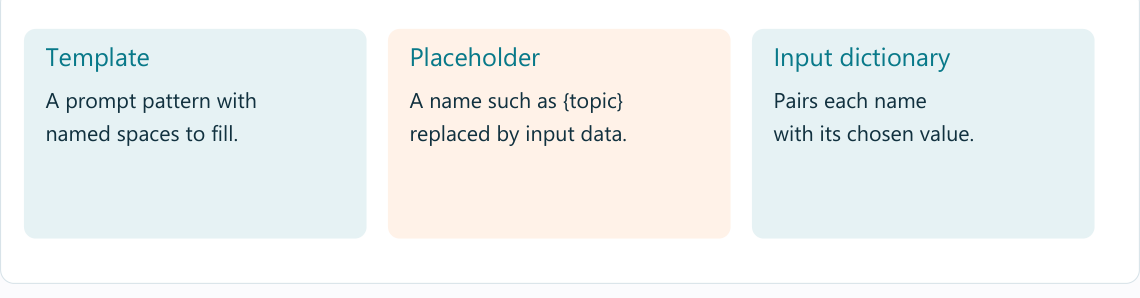

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

A chat prompt template fills named inputs and keeps message roles.

In [7]:
from langchain_core.prompts import ChatPromptTemplate

The two placeholders are input keys; the system message stays the same.

In [8]:
prompt = ChatPromptTemplate.from_messages([("system", "Explain to a beginner."), ("human", "Explain {topic} in {points} short points.")])

In [9]:
values = {"topic": "Python lists", "points": 2}

Inspect the filled role messages before asking the model.

In [10]:
filled = prompt.invoke(values)
filled.to_messages()

[SystemMessage(content='Explain to a beginner.', additional_kwargs={}, response_metadata={}),
 HumanMessage(content='Explain Python lists in 2 short points.', additional_kwargs={}, response_metadata={})]

In [11]:
print(llm.invoke(filled).content)

Here are two short points explaining Python lists:

**1. What is a List?**
A list in Python is an ordered collection of items that can be of any data type, including strings, integers, floats, and other lists. Lists are denoted by square brackets `[]` and are used to store multiple values in a single variable.

**2. Basic Operations with Lists**
You can perform various operations on lists, such as:
* Indexing: accessing a specific element using its index (e.g., `my_list[0]`)
* Slicing: extracting a subset of elements using a range (e.g., `my


In [12]:
fresh = prompt.invoke({"topic": "Python dictionaries", "points": 3})

In [13]:
print(llm.invoke(fresh).content)

Here are three short points explaining Python dictionaries:

**1. What is a Dictionary?**
A dictionary is an unordered collection of key-value pairs, where each key is unique and maps to a specific value.

**2. How to Create a Dictionary**
You can create a dictionary using curly brackets `{}` and assigning values to keys using the `=` operator, e.g., `my_dict = {"name": "John", "age": 30}`.

**3. Accessing Values in a Dictionary**
To access a value in a dictionary, you use the key that corresponds to it, separated by a dot or square brackets, e.g


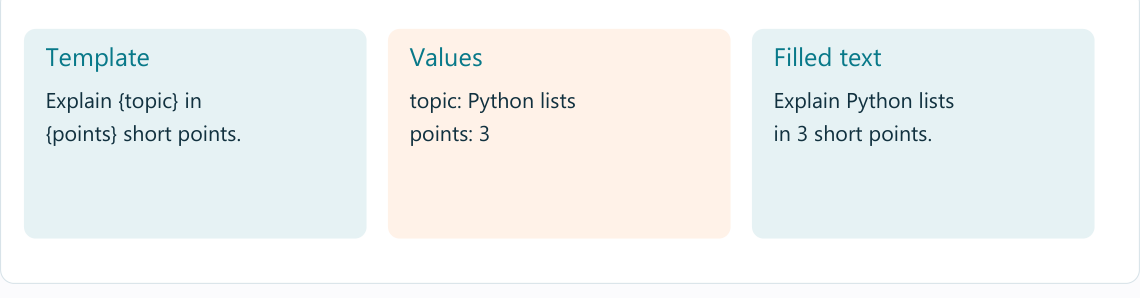

## Try a fresh input

Try the second topic as a fresh input. Keep the rule and output shape unchanged.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/prompt-templates).